In [30]:
import os
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import pytorch_lightning as pl
from pytorch_lightning import Trainer
import matplotlib.pyplot as plt
import numpy as np


In [40]:
# Parameters
batch_size = 32
img_height = 180
img_width = 180
generator1 = torch.Generator().manual_seed(43)

# Data transforms
transform = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

transformJitter = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.ColorJitter(hue=0.1, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])


# Load dataset
data_dir = "../Dataset"
train_data = datasets.ImageFolder(root=data_dir, transform=transform)
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(train_data, [train_size, val_size], generator=generator1)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
class_names = train_data.classes  # To map labels to names later


In [32]:
type(val_dataset)

torch.utils.data.dataset.Subset

In [41]:
for image, label in val_dataset:
    #break

    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0) 
    
    # Plot the image
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')
    plt.show()


In [34]:
class SimpleCNN(pl.LightningModule):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(128 * (img_height // 8) * (img_width // 8), 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )
        self.criterion = nn.BCELoss()

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        y = y.float().view(-1, 1)
        y_hat = self(x)
        loss = self.criterion(y_hat, y)
        self.log("train_loss", loss)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        y = y.float().view(-1, 1)
        y_hat = self(x)
        val_loss = self.criterion(y_hat, y)
        preds = (y_hat > 0.5).float()
        acc = (preds == y).float().mean()
        self.log("val_loss", val_loss, prog_bar=True)
        self.log("val_acc", acc, prog_bar=True)
        return {'val_loss': val_loss, 'val_acc': acc, 'preds': preds, 'y': y}

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=1e-3)


In [35]:
model = SimpleCNN()
trainer = Trainer(max_epochs=3)
trainer.fit(model, train_loader, val_loader)


GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs

  | Name      | Type       | Params | Mode 
-------------------------------------------------
0 | model     | Sequential | 8.0 M  | train
1 | criterion | BCELoss    | 0      | train
-------------------------------------------------
8.0 M     Trainable params
0         Non-trainable params
8.0 M     Total params
32.093    Total estimated model params size (MB)
16        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=3` reached.


Amount of Misclassification: 14


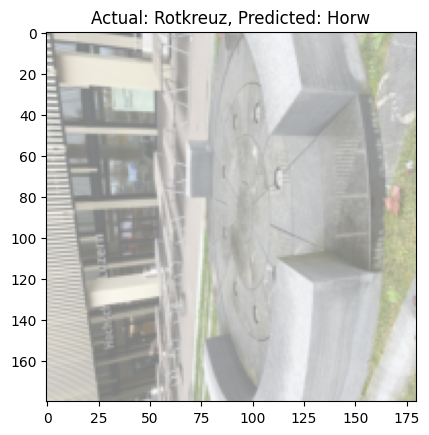

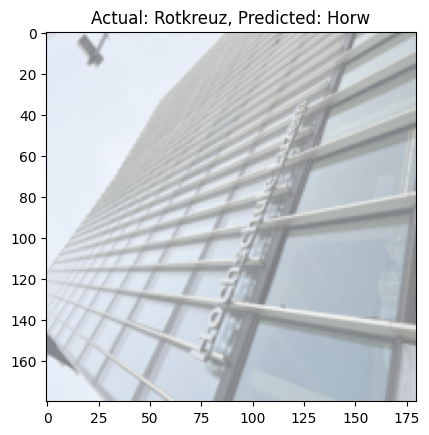

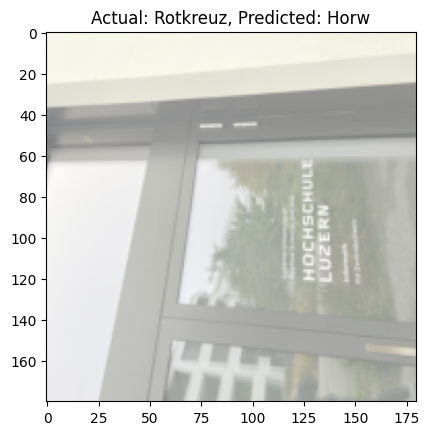

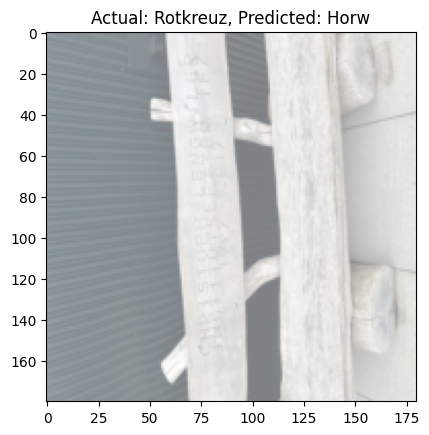

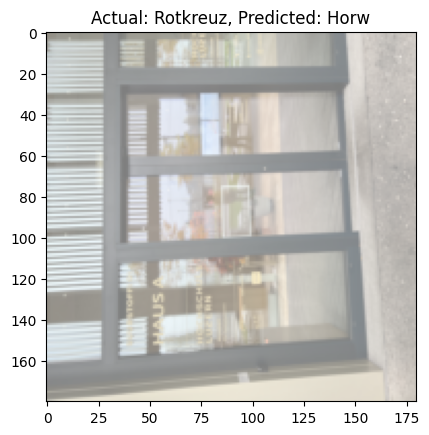

In [37]:
# Helper function to unnormalize and display images
def imshow(img, title):
    img = img / 2 + 0.5  # Unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.title(title)
    plt.show()

# Evaluate on validation set
model.eval()
misclassified_images = []
actual_labels = []
predicted_labels = []

with torch.no_grad():
    for batch in val_loader:
        images, labels = batch
        outputs = model(images)
        preds = (outputs > 0.5).float().view(-1)

        for i in range(len(labels)):
            if preds[i] != labels[i]:  # Misclassified
                misclassified_images.append(images[i])
                actual_labels.append(class_names[labels[i].item()])
                predicted_labels.append(class_names[int(preds[i].item())])

print(f'Amount of Misclassification: {len(misclassified_images)}')

# Display a few misclassified images
for i in range(min(5, len(misclassified_images))):
    imshow(misclassified_images[i], f"Actual: {actual_labels[i]}, Predicted: {predicted_labels[i]}")


# Cleaned Dataset

In [38]:
data_dir = "../Dataset_Clean"
train_data = datasets.ImageFolder(root=data_dir, transform=transform)
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(train_data, [train_size, val_size], generator=generator1)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
class_names = train_data.classes  # To map labels to names later

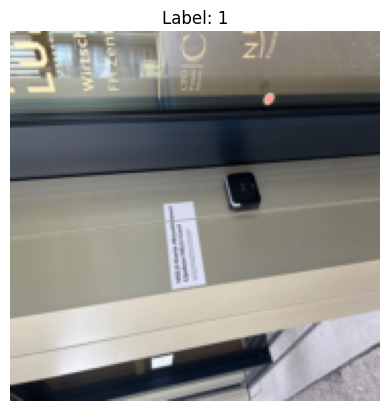

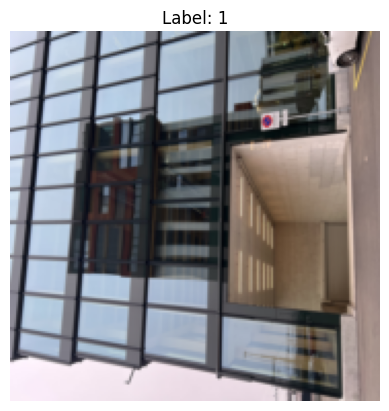

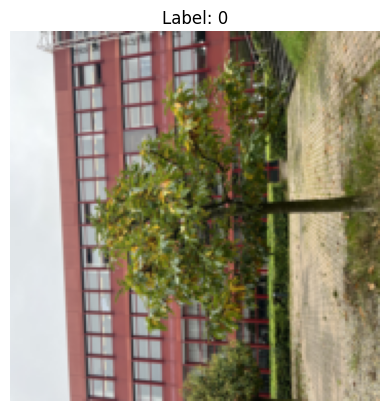

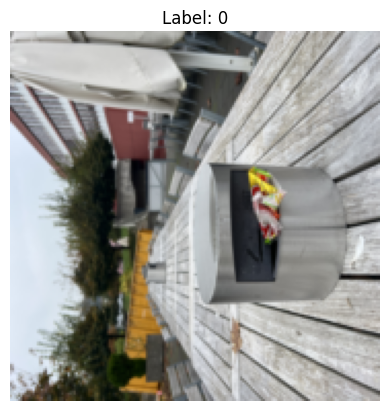

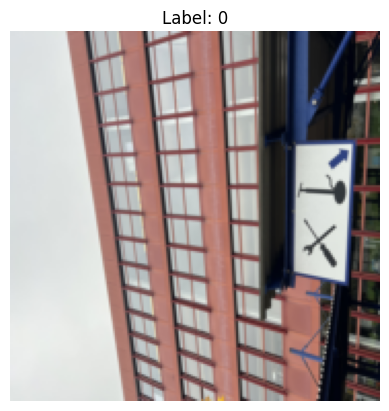

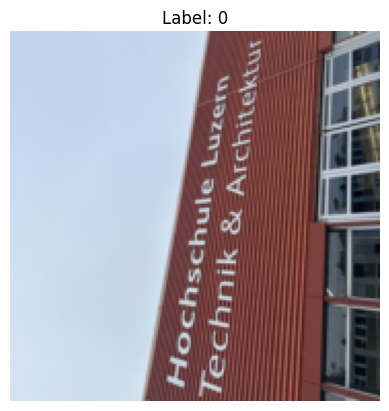

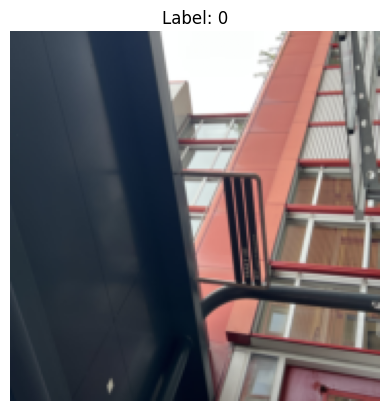

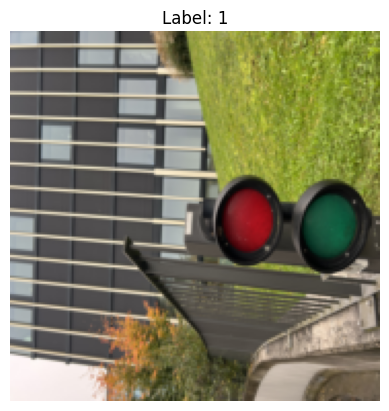

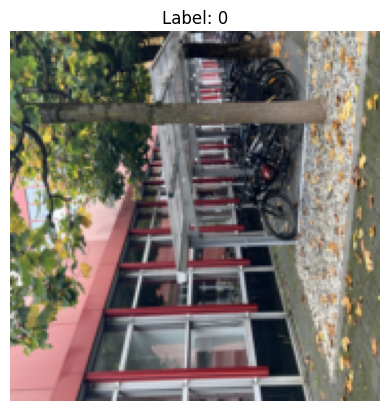

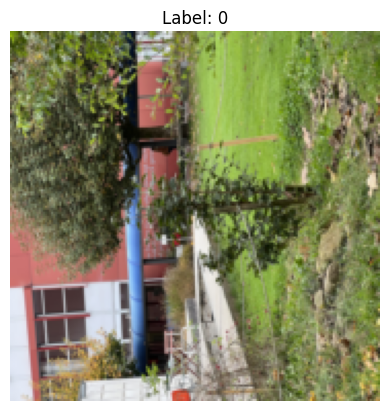

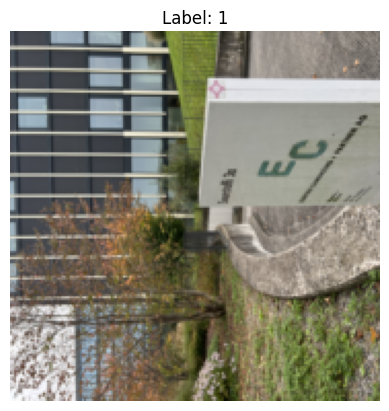

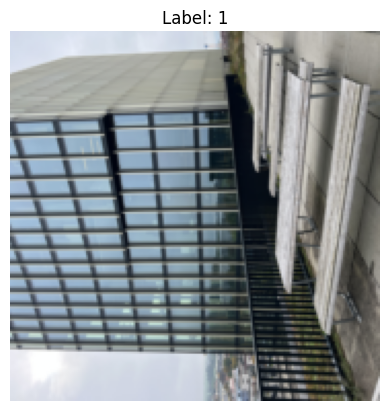

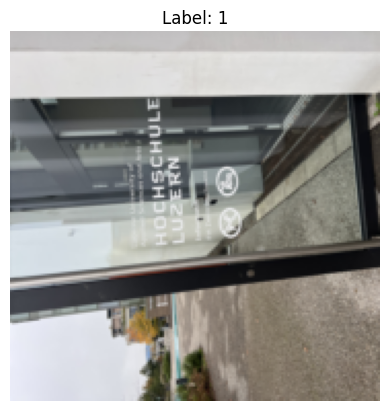

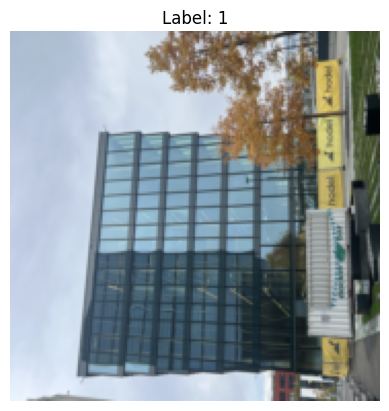

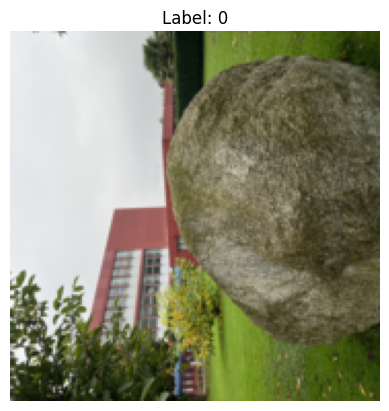

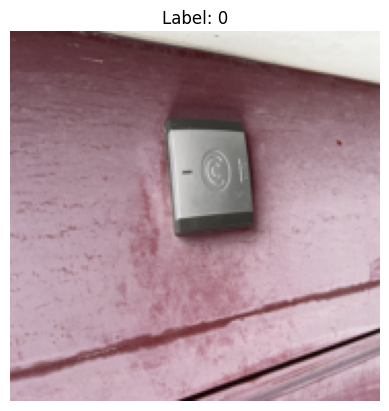

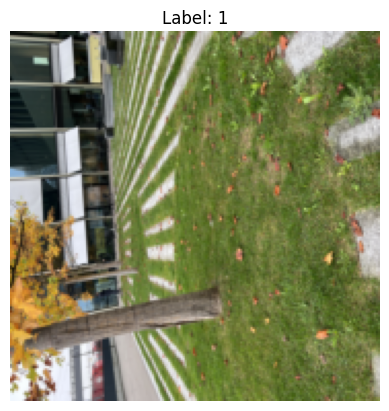

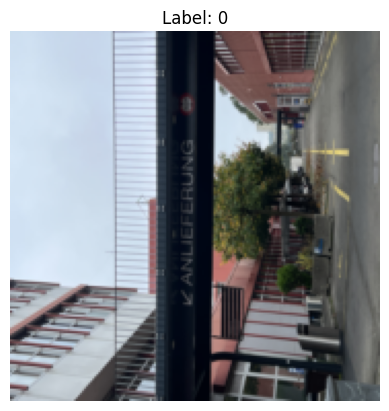

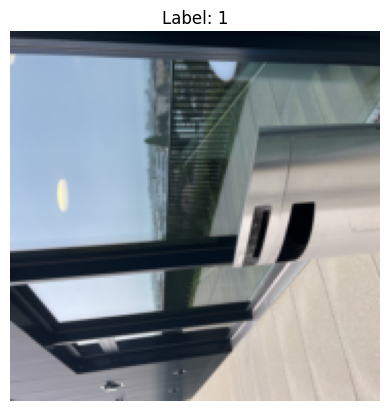

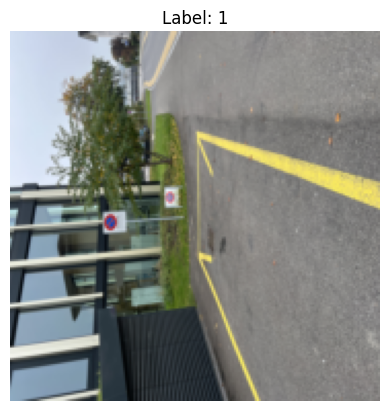

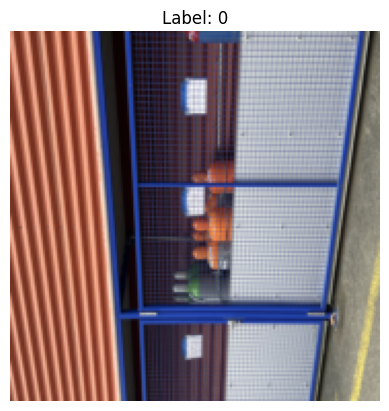

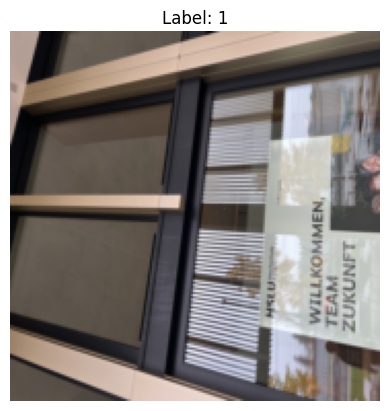

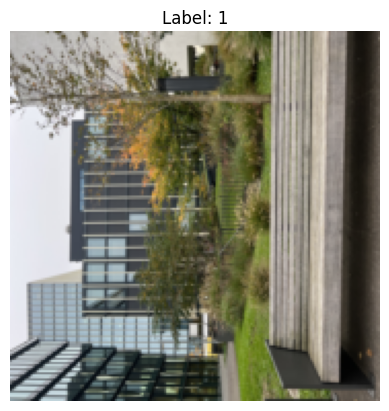

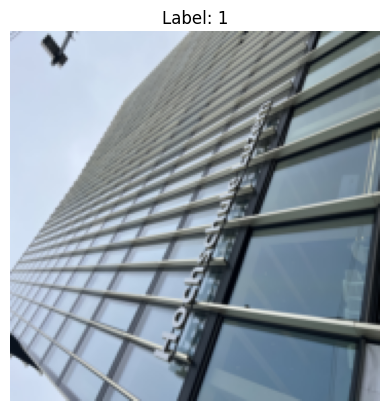

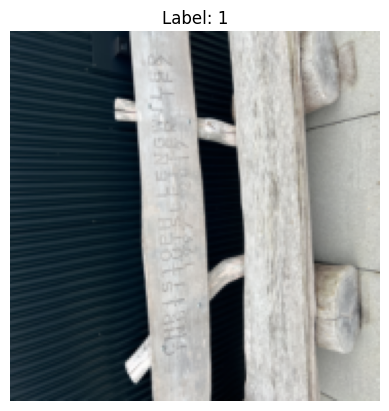

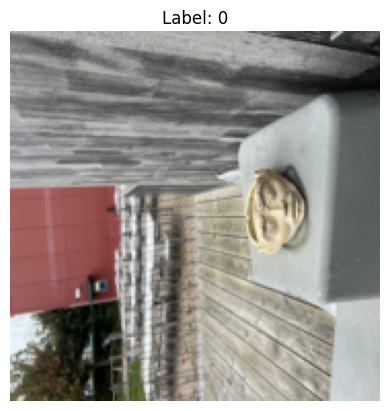

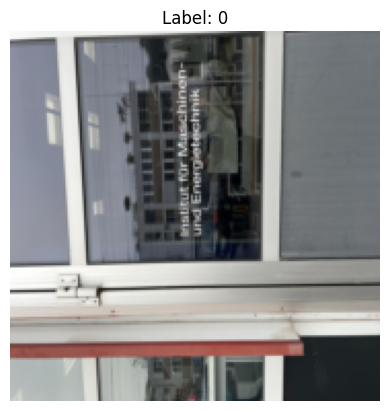

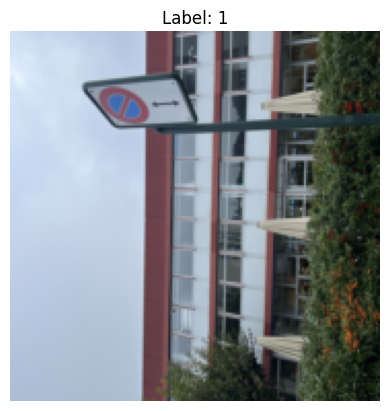

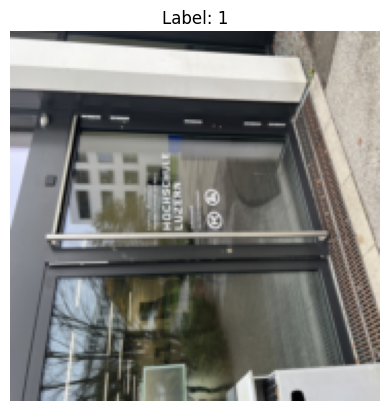

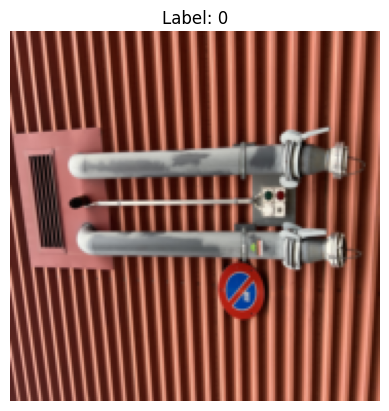

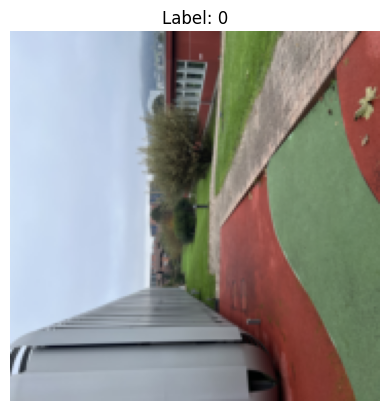

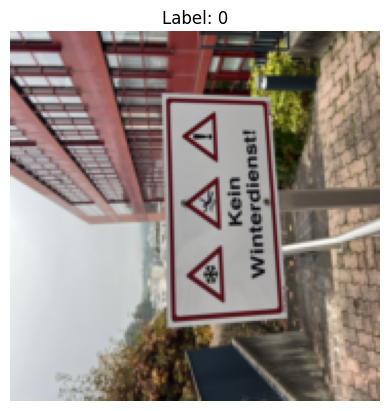

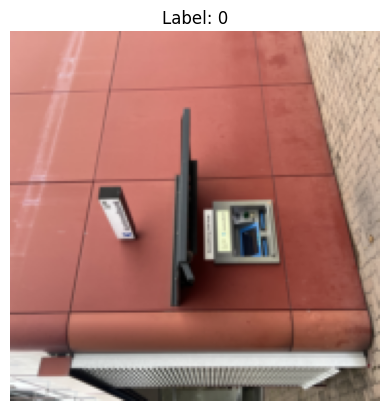

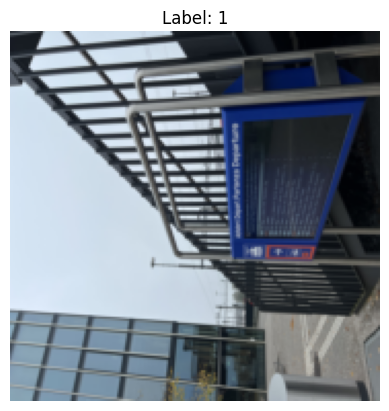

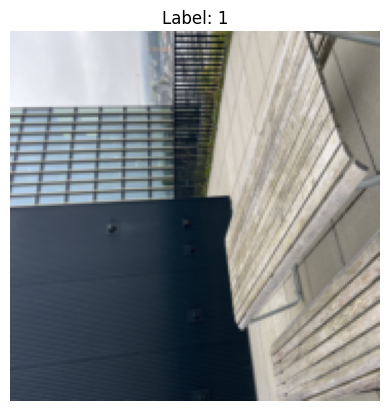

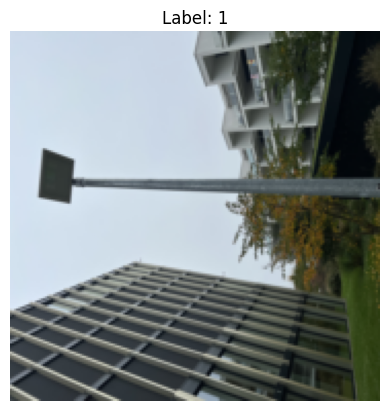

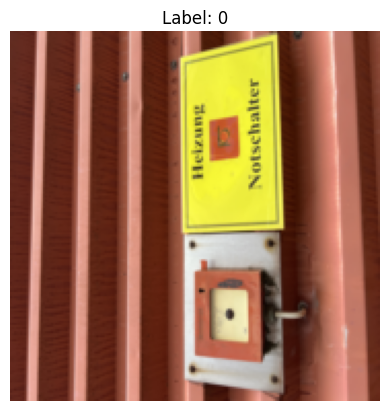

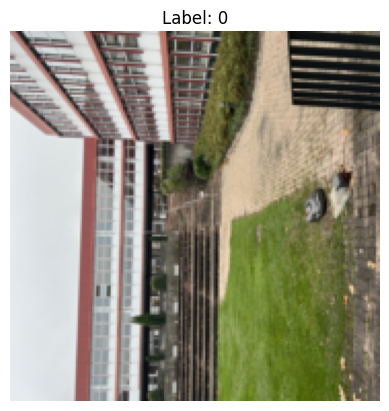

In [39]:
for image, label in val_dataset:


    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0) 
    
    # Plot the image
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')
    plt.show()
